# m05 - Classifying the Recommended Crop

The written report's recommendation map is a rule applied to the ten GAEZ indices (here at 1 km): the crop with the highest index wins, unless even
the best index is below 5,000 ("Not recommended"). This notebook asks how well that *label* can be recovered from the 14
physical drivers, in two ways:

* **Direct**: classifiers trained on the label.
* **Regress, then apply the rule**: the surrogate regressors of notebook m01 predict the ten indices, then the same rule is
  applied to the predictions.

Targets: `thresh` (winner or "Not recommended") and `top` (plain argmax). Pixel-grouped CV vs random K-fold, 2 repeats.
Metrics that survive class imbalance matter here (balanced accuracy, macro-F1), because accuracy alone rewards predicting the
majority class.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
y_thr_s, y_top_s = E.crop_labels(df, "thresh"), E.crop_labels(df, "top")
# full label sets: the regress-then-rule route can predict crops that never win in the data
classes_thr, classes_top = sorted(E.CROPS + ["Not recommended"]), sorted(E.CROPS)
y_thr = y_thr_s.map({c: i for i, c in enumerate(classes_thr)}).to_numpy()
y_top = y_top_s.map({c: i for i, c in enumerate(classes_top)}).to_numpy()

counts = pd.DataFrame({"thresh": y_thr_s.value_counts(), "top": y_top_s.value_counts()}).fillna(0).astype(int)
counts["pixels_where_it_wins (thresh)"] = y_thr_s.groupby(y_thr_s).apply(lambda s: df.loc[s.index, "pix"].nunique())
print("majority-class share  thresh: %.3f   top: %.3f" % (y_thr_s.value_counts(normalize=True).iloc[0], y_top_s.value_counts(normalize=True).iloc[0]))
counts.sort_values("thresh", ascending=False)

majority-class share  thresh: 0.558   top: 0.470


,thresh,top,pixels_where_it_wins (thresh)
label,,,
Not recommended,5091,0,139.0
coconut,2166,2707,58.0
oilpalm,1769,4293,74.0
cacao,51,132,5.0
coffee,50,199,15.0
cassava,1,26,1.0
rice,1,329,1.0
maize,0,3,NaN
rubber,0,1440,NaN


## 1. Direct classification

In [3]:
MODELS = ["dummy", "logreg", "knn", "et", "hgb", "xgb"]
SCHEMES = ["random", "pixel"]
clf_res, clf_oof = E.run_grid(df, {"thresh": y_thr, "top": y_top}, MODELS, SCHEMES, kind="clf", n_repeats=2, keep_oof=True)
E.save_table(clf_res, "m05_direct_raw")
t = clf_res.groupby(["target", "model", "scheme"])[["accuracy", "balanced_acc", "macro_f1"]].mean().unstack("scheme")
t.round(3)

48 tasks (6 models x 2 targets x 2 schemes x 2 repeats), 14 features


done in 29 s


accuracy        balanced_acc        macro_f1       
scheme           pixel random        pixel random    pixel random
target model                                                     
thresh dummy     0.558  0.558        0.143  0.143    0.102  0.102
       et        0.845  0.913        0.511  0.597    0.508  0.580
       hgb       0.855  0.911        0.471  0.585    0.480  0.572
       knn       0.807  0.884        0.469  0.538    0.489  0.552
       logreg    0.725  0.740        0.520  0.574    0.377  0.397
       xgb       0.855  0.907        0.433  0.548    0.461  0.566
top    dummy     0.470  0.470        0.125  0.125    0.080  0.080
       et        0.824  0.926        0.518  0.777    0.530  0.741
       hgb       0.827  0.927        0.499  0.769    0.506  0.742
       knn       0.787  0.892        0.442  0.634    0.466  0.671
       logreg    0.684  0.724        0.551  0.726    0.422  0.514
       xgb       0.822  0.921        0.442  0.695    0.482  0.722

## 2. Regress the indices, then apply the rule

In [4]:
REG_MODELS = ["hgb", "xgb"]
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)
reg_res, reg_oof = E.run_grid(df, targets, REG_MODELS, SCHEMES, n_repeats=2, keep_oof=True, verbose=False)

def to_labels(P, mode):
    best = P.argmax(axis=1)
    names = np.array(E.CROPS, dtype=object)[best]
    if mode == "thresh":
        names = np.where(P.max(axis=1) < E.NOT_RECOMMENDED_THRESHOLD, "Not recommended", names)
    return names

rows = []
for m in REG_MODELS:
    for s in SCHEMES:
        for r in range(2):
            P = np.column_stack([reg_oof[(m, c, s, r)] for c in E.CROPS])
            for mode, truth_s, classes in [("thresh", y_thr_s, classes_thr), ("top", y_top_s, classes_top)]:
                pred = pd.Series(to_labels(P, mode)).map({c: i for i, c in enumerate(classes)}).to_numpy()
                truth = truth_s.map({c: i for i, c in enumerate(classes)}).to_numpy()
                rows.append({"target": mode, "model": f"{m} + rule", "scheme": s, "repeat": r, **E.classification_metrics(truth, pred)})
rule_res = pd.DataFrame(rows)
E.save_table(rule_res, "m05_regress_then_rule_raw")
both = pd.concat([clf_res.assign(route="direct"), rule_res.assign(route="regress+rule")], ignore_index=True)
board = both.groupby(["target", "scheme", "model"])[["accuracy", "balanced_acc", "macro_f1"]].mean().round(3)
E.save_table(board, "m05_leaderboard", index=True)
board.loc["thresh", "pixel"].sort_values("macro_f1", ascending=False)

,accuracy,balanced_acc,macro_f1
model,,,
et,0.845,0.511,0.508
knn,0.807,0.469,0.489
hgb,0.855,0.471,0.480
xgb,0.855,0.433,0.461
hgb + rule,0.792,0.442,0.418
logreg,0.725,0.520,0.377
xgb + rule,0.798,0.404,0.366
dummy,0.558,0.143,0.102


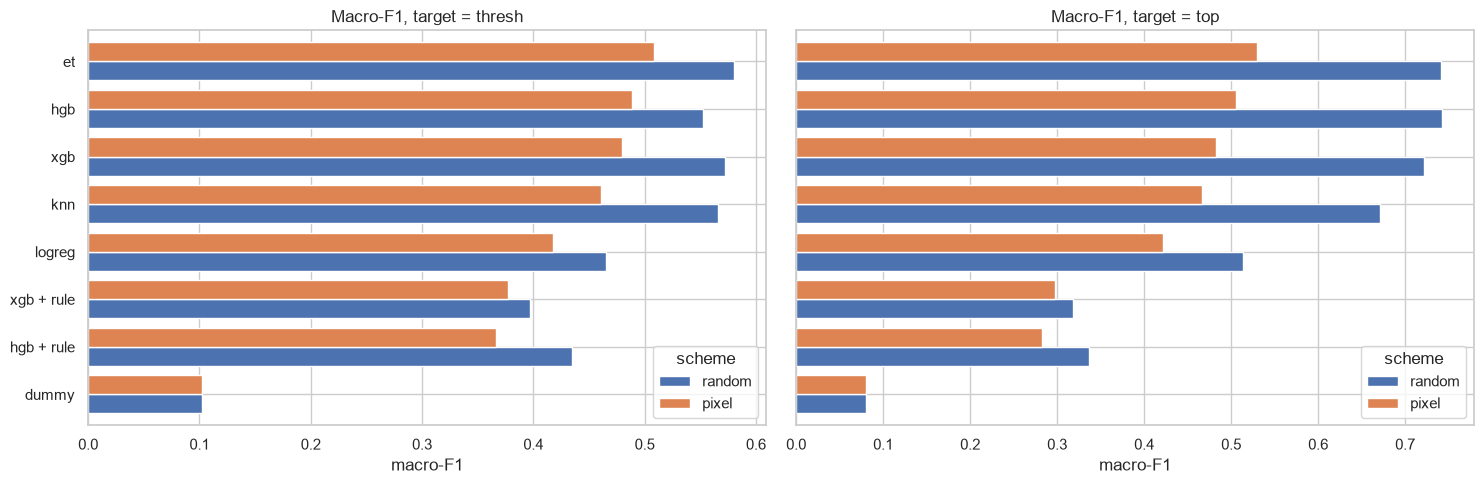

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, target in zip(axes, ["thresh", "top"]):
    sub = board.loc[target].reset_index().pivot(index="model", columns="scheme", values="macro_f1")[["random", "pixel"]]
    sub = sub.sort_values("pixel")
    sub.plot.barh(ax=ax, width=0.8)
    ax.set(title=f"Macro-F1, target = {target}", xlabel="macro-F1", ylabel="")
plt.tight_layout()
E.save_fig(fig, "m05_macro_f1")
plt.show()

## 3. Where does the best honest model go wrong?

best model for target=thresh under pixel CV: et


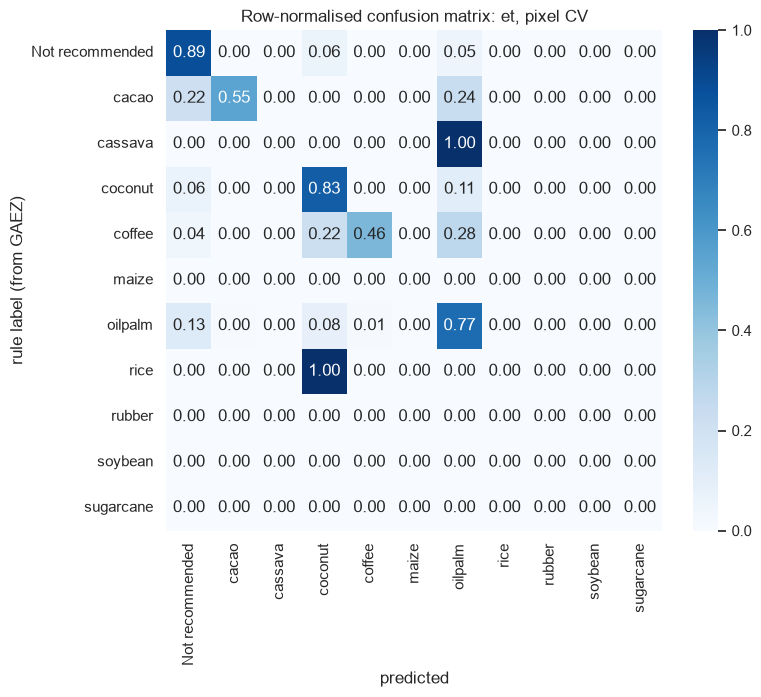

,precision,recall,f1-score,support
Not recommended,0.922,0.885,0.903,5091.000
cacao,0.757,0.549,0.636,51.000
cassava,0.000,0.000,0.000,1.000
coconut,0.792,0.825,0.808,2166.000
coffee,0.411,0.460,0.434,50.000
maize,0.000,0.000,0.000,0.000
oilpalm,0.719,0.769,0.743,1769.000
rice,0.000,0.000,0.000,1.000
rubber,0.000,0.000,0.000,0.000
soybean,0.000,0.000,0.000,0.000


In [6]:
from sklearn.metrics import classification_report, confusion_matrix

best_name = board.loc["thresh", "pixel"].drop(index=[i for i in board.loc["thresh", "pixel"].index if i.startswith("dummy")]).sort_values("macro_f1").index[-1]
print("best model for target=thresh under pixel CV:", best_name)
if best_name.endswith("+ rule"):
    m = best_name.replace(" + rule", "")
    P = np.column_stack([reg_oof[(m, c, "pixel", 0)] for c in E.CROPS])
    pred = pd.Series(to_labels(P, "thresh")).map({c: i for i, c in enumerate(classes_thr)}).to_numpy()
else:
    pred = clf_oof[(best_name, "thresh", "pixel", 0)]
cm = confusion_matrix(y_thr, pred, labels=range(len(classes_thr)), normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes_thr, yticklabels=classes_thr, ax=ax)
ax.set(title=f"Row-normalised confusion matrix: {best_name}, pixel CV", xlabel="predicted", ylabel="rule label (from GAEZ)")
E.save_fig(fig, "m05_confusion")
plt.show()
rep = pd.DataFrame(classification_report(y_thr, pred, labels=range(len(classes_thr)), target_names=classes_thr,
                                         output_dict=True, zero_division=0)).T
rep.round(3)

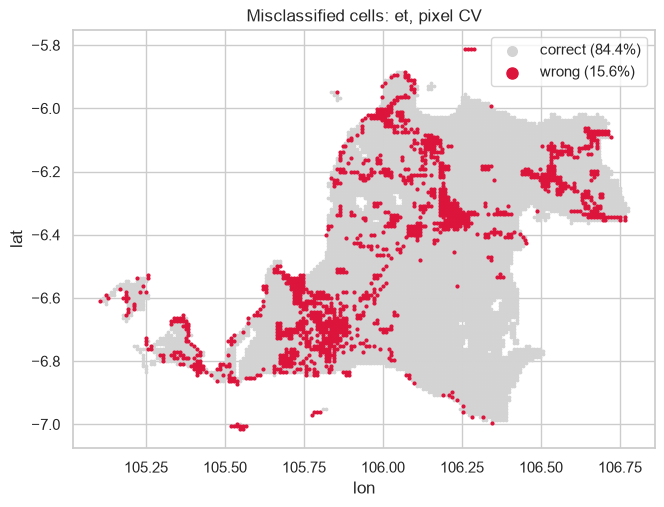

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ok = pred == y_thr
ax.scatter(df.loc[ok, "lon"], df.loc[ok, "lat"], s=3, c="lightgrey", label=f"correct ({ok.mean():.1%})")
ax.scatter(df.loc[~ok, "lon"], df.loc[~ok, "lat"], s=4, c="crimson", label=f"wrong ({(~ok).mean():.1%})")
ax.set(title=f"Misclassified cells: {best_name}, pixel CV", xlabel="lon", ylabel="lat", aspect="equal")
ax.legend(markerscale=4)
E.save_fig(fig, "m05_error_map")
plt.show()

## 4. One crop at a time: is a cell suitable (index >= 5,000)?

In [8]:
suit = {c: (df[E.target_col(c)] >= E.NOT_RECOMMENDED_THRESHOLD).astype(int).to_numpy() for c in E.CROPS}
prev = pd.Series({c: v.mean() for c, v in suit.items()}, name="prevalence").round(3)
keep_crops = [c for c in E.CROPS if 0.03 <= suit[c].mean() <= 0.97]
print("prevalence of 'suitable' per crop:\n", prev.to_string(), "\nevaluated (3-97% prevalence):", keep_crops)
bin_res, _ = E.run_grid(df, {c: suit[c] for c in keep_crops}, ["dummy", "logreg", "et", "hgb", "xgb"], SCHEMES, kind="clf", n_repeats=2, verbose=False)
E.save_table(bin_res, "m05_binary_suitability_raw")
bt = bin_res.groupby(["model", "scheme"])[["balanced_acc", "macro_f1"]].mean().unstack("scheme")
bt.round(3)

prevalence of 'suitable' per crop:
 rice         0.239
maize        0.001
cassava      0.335
soybean      0.028
oilpalm      0.431
rubber       0.000
sugarcane    0.130
coffee       0.339
cacao        0.274
coconut      0.317 
evaluated (3-97% prevalence): ['rice', 'cassava', 'oilpalm', 'sugarcane', 'coffee', 'cacao', 'coconut']


balanced_acc        macro_f1       
scheme        pixel random    pixel random
model                                     
dummy         0.500  0.500    0.412  0.412
et            0.895  0.939    0.889  0.929
hgb           0.903  0.935    0.888  0.920
logreg        0.867  0.879    0.834  0.844
xgb           0.888  0.921    0.889  0.921

In [9]:
pivot = bin_res[bin_res.scheme == "pixel"].groupby(["target", "model"])["balanced_acc"].mean().unstack("model").drop(columns="dummy")
pivot.insert(0, "prevalence", prev.reindex(pivot.index))
E.save_table(pivot.round(4), "m05_binary_by_crop_pixel", index=True)
pivot.round(3)

model,prevalence,et,hgb,logreg,xgb
target,,,,,
cacao,0.274,0.894,0.903,0.880,0.889
cassava,0.335,0.893,0.901,0.865,0.899
coconut,0.317,0.886,0.892,0.841,0.881
coffee,0.339,0.885,0.891,0.846,0.883
oilpalm,0.431,0.892,0.898,0.850,0.897
rice,0.239,0.916,0.918,0.881,0.902
sugarcane,0.130,0.897,0.917,0.909,0.867
